In [4]:
from node import Node, simulation, Loglist
import time
import matplotlib.pyplot as plt

In [5]:
simulation(3, 10, 0.5, seed=10)
for entry in Loglist:
    print(entry)

[2, 1, (0, 0, 1), 'sent: I cut my finger slicing cheese the other day...<>but I think I may have grater problems than that.']
[1, 2, (0, 1, 1), 'recv: I cut my finger slicing cheese the other day...<>but I think I may have grater problems than that.']
[0, 1, (1, 0, 0), 'sent: What do you call a snowman with a six-pack?<>An abdominal snowman.']
[2, 2, (1, 0, 2), 'recv: What do you call a snowman with a six-pack?<>An abdominal snowman.']
[2, 3, (1, 0, 3), 'If you want to get a job at the moisturizer factory... <>you’re going to have to apply daily.']
[2, 4, (1, 0, 4), 'sent: What do you call a bear with no teeth?<>A gummy bear.']
[0, 5, (2, 0, 4), 'recv: What do you call a bear with no teeth?<>A gummy bear.']
[2, 5, (1, 0, 5), 'If you see a robbery at an Apple Store what re you?<> An iWitness?']
[1, 3, (0, 2, 1), 'What do you call a bear with no teeth?<>A gummy bear.']
[1, 4, (0, 3, 1), 'sent: Why did the broom get promoted?<>Because it swept the competition.']
[2, 6, (1, 3, 6), 'recv: W

In [19]:
def vector_less(Va, Vb):
    # True if Va happened before Vb: every entry <= and not identical
    return all(x <= y for x, y in zip(Va, Vb)) and Va != Vb

def clocks_increase(before, after):
    # True if BOTH the Lamport and the vector timestamp go up
    return before[1] < after[1] and vector_less(before[2], after[2])

def check_log(log):
    checked = 0
    errors = 0
    last_on_node = {}
    for i in range(len(log)):
        event = log[i]
        node = event[0]

        # Rule 1: the previous event on the same node happened before this one
        if node in last_on_node:
            checked += 1
            if not clocks_increase(last_on_node[node], event):
                errors += 1
        last_on_node[node] = event

        # Rule 2: a send happened before its receive (always the next entry)
        if event[3].startswith("sent: "):
            checked += 1
            if not clocks_increase(event, log[i + 1]):
                errors += 1

    return checked, errors

In [20]:
total_checked = total_errors = 0
for seed in range(10):
    checked, errors = check_log(simulation(5, 200, 0.5, seed))
    total_checked += checked
    total_errors += errors
print(f"Checked {total_checked} links, errors: {total_errors}")

Checked 3912 links, errors: 0


In [21]:
log = simulation(3, 8, 0.5, seed=3)
last_on_node = {}

print(f"{'#':<3} {'Node':<5} {'Type':<9} {'Lamport':<8} {'Vector':<11} Check")
for i in range(len(log)):
    node, L, V, msg = log[i]
    if msg.startswith("sent: "):
        kind = "send"
    elif msg.startswith("recv: "):
        kind = "receive"
    else:
        kind = "internal"

    checks = []
    if node in last_on_node:                       # rule 1
        j = last_on_node[node]
        checks.append(f"after #{j}: {'OK' if clocks_increase(log[j], log[i]) else 'ERROR'}")
    if kind == "receive":                          # rule 2
        checks.append(f"after send #{i-1}: {'OK' if clocks_increase(log[i-1], log[i]) else 'ERROR'}")
    last_on_node[node] = i

    print(f"{i:<3} P{node+1:<4} {kind:<9} {L:<8} {str(V):<11} {', '.join(checks)}")

#   Node  Type      Lamport  Vector      Check
0   P1    internal  1        (1, 0, 0)   
1   P2    internal  1        (0, 1, 0)   
2   P3    internal  1        (0, 0, 1)   
3   P2    send      2        (0, 2, 0)   after #1: OK
4   P1    receive   3        (2, 2, 0)   after #0: OK, after send #3: OK
5   P3    send      2        (0, 0, 2)   after #2: OK
6   P2    receive   3        (0, 3, 2)   after #3: OK, after send #5: OK
7   P3    internal  3        (0, 0, 3)   after #5: OK
8   P3    send      4        (0, 0, 4)   after #7: OK
9   P2    receive   5        (0, 4, 4)   after #6: OK, after send #8: OK
10  P3    internal  5        (0, 0, 5)   after #8: OK


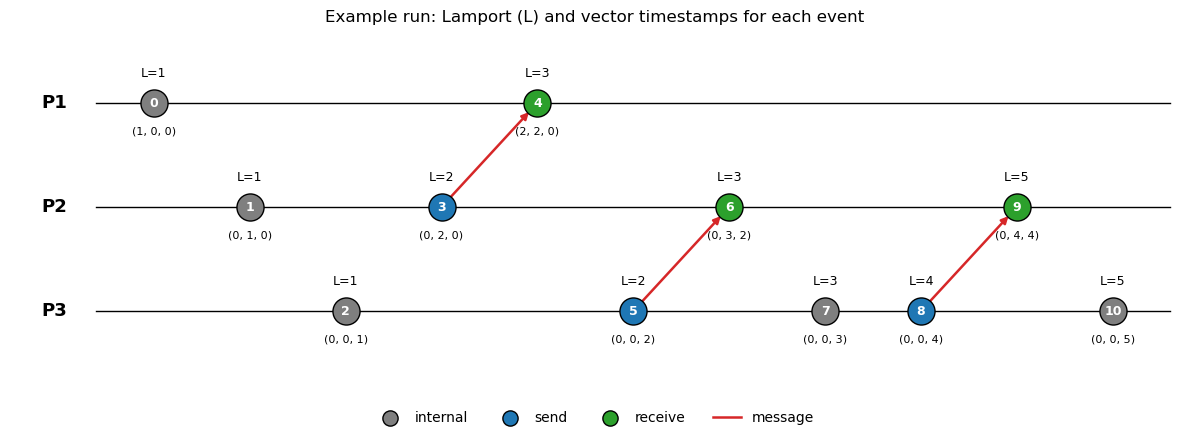

In [22]:
import matplotlib.pyplot as plt

log = simulation(3, 8, 0.5, seed=3)
N = 3
colors = {"internal": "tab:gray", "send": "tab:blue", "receive": "tab:green"}

def event_type(msg):
    if msg.startswith("sent: "): return "send"
    if msg.startswith("recv: "): return "receive"
    return "internal"

fig, ax = plt.subplots(figsize=(12, 4.5))

# one horizontal line per node (P1 at the top)
for n in range(N):
    y = N - 1 - n
    ax.plot([-0.6, len(log) - 0.4], [y, y], color="black", linewidth=1, zorder=1)
    ax.text(-0.9, y, f"P{n+1}", ha="right", va="center", fontsize=13, fontweight="bold")

# messages: arrow from each send to the next entry (its receive)
for i in range(len(log)):
    if event_type(log[i][3]) == "send":
        x1, y1 = i, N - 1 - log[i][0]
        x2, y2 = i + 1, N - 1 - log[i + 1][0]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=1.8,
                                    shrinkA=9, shrinkB=9), zorder=2)

# events: dot with event number, Lamport above, vector below
for i, (node, L, V, msg) in enumerate(log):
    x, y = i, N - 1 - node
    ax.scatter(x, y, s=380, color=colors[event_type(msg)], edgecolor="black", zorder=3)
    ax.text(x, y, str(i), ha="center", va="center", color="white",
            fontsize=9, fontweight="bold", zorder=4)
    ax.text(x, y + 0.22, f"L={L}", ha="center", va="bottom", fontsize=9)
    ax.text(x, y - 0.22, str(V), ha="center", va="top", fontsize=8)

# legend
for kind, c in colors.items():
    ax.scatter([], [], s=120, color=c, edgecolor="black", label=kind)
ax.plot([], [], color="tab:red", lw=1.8, label="message")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=4, frameon=False)

ax.set_xlim(-1.5, len(log) - 0.3)
ax.set_ylim(-0.7, N - 0.3)
ax.axis("off")
ax.set_title("Example run: Lamport (L) and vector timestamps for each event", fontsize=12)
plt.tight_layout()
plt.savefig("example_run.png", dpi=150, bbox_inches="tight")
plt.show()